Modelling and Evaluation Notebook

Objectives

To investigate if artificial intelligence can identify fetus intracranial structures in pregnancy weeks 11–14

Inputs
inputs/Dataset_Clean/train
inputs/Dataset_Clean/test
inputs/Dataset_Clean/validation
image shape embeddings


Outputs
Images distribution plot in train, validation and test sets
Image augmentation
Class indices to change prediction inference in labels
Machine learning model creation and training
Save model
Learning curve plot for model performance
Model evaluation on pickle file
Prediction on the random image file

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.image import imread

In [3]:
cwd= os.getcwd()

In [4]:
os.chdir('c:/python_projects/ML_2/jupyter_notebooks')
print("You set a new current directory")

You set a new current directory


In [5]:
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\ML_2\\jupyter_notebooks'

In [6]:
my_data_dir='inputs/Dataset_Clean/standard_and_non_standard'
train_path=my_data_dir +'/train'
validation_path=my_data_dir + '/validation'
test_path=my_data_dir + '/test'

In [7]:
train_path = r'C:\python_projects\ML_2\inputs\Dataset_Clean\train'
labels = os.listdir(train_path)
print('Label for the images are', labels)

Label for the images are ['Non-Standard', 'Standard']


In [8]:
print(f"Train path: {train_path}")
print(f"Labels: {labels}")

Train path: C:\python_projects\ML_2\inputs\Dataset_Clean\train
Labels: ['Non-Standard', 'Standard']


In [9]:
import os
print("Current working directory:", os.getcwd())

Current working directory: c:\python_projects\ML_2\jupyter_notebooks


In [10]:
import os
my_data_dir='inputs/Dataset_Clean/standard_and_non_standard'
train_path=my_data_dir +'/train'
validation_path=my_data_dir + '/validation'
test_path=my_data_dir + '/test'

In [11]:
version='v1'
file_path=f'outputs/{version}'
if os.path.exists(file_path):
    print('Old version is already available. Create a new version if needed.')
else:
    os.makedirs(file_path)
    print(f'Created new folder: {file_path}')
    


Old version is already available. Create a new version if needed.


In [12]:
train_path = '../inputs/Dataset_Clean/standard_and_non_standard/train'

labels = ['Standard', 'Non-Standard']

In [13]:
from pathlib import Path

file_path = Path(
    r"C:\python_projects\ML_2\outputs\v1\image_shape.pkl"
)

print("File exists:", file_path.exists())

File exists: True


In [14]:
from pathlib import Path
import joblib

image_shape = (256, 256)

output_dir = Path(r"C:\python_projects\ML_2\outputs\v1")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(image_shape, output_dir / "image_shape.pkl")

print("Image shape saved:", image_shape)

Image shape saved: (256, 256)


In [15]:
import joblib

version = 'v1'

image_shape = joblib.load(
    filename=f"../outputs/{version}/image_shape.pkl"
)

print("Image shape:", image_shape)

Image shape: (256, 256)


In [16]:
from pathlib import Path

version = "v1"

output_dir = Path(r"C:\python_projects\ML_2\outputs") / version

output_dir.mkdir(parents=True, exist_ok=True)

print("Output directory:", output_dir)

Output directory: C:\python_projects\ML_2\outputs\v1


In [17]:
from pathlib import Path

# Correct dataset directory
data_dir = Path(r"C:\python_projects\ML_2\inputs\Dataset_Clean")

train_path = data_dir / "train"
validation_path = data_dir / "validation"
test_path = data_dir / "test"

print("Train exists:", train_path.exists())
print("Validation exists:", validation_path.exists())
print("Test exists:", test_path.exists())

Train exists: True
Validation exists: True
Test exists: True


In [18]:
labels = ["Standard", "Non-Standard"]

for split in ["train", "validation", "test"]:
    for label in labels:
        folder = data_dir / split / label

        if folder.is_dir():
            print(f"Found: {folder}")
        else:
            print(f"Folder not found: {folder}")

Found: C:\python_projects\ML_2\inputs\Dataset_Clean\train\Standard
Found: C:\python_projects\ML_2\inputs\Dataset_Clean\train\Non-Standard
Found: C:\python_projects\ML_2\inputs\Dataset_Clean\validation\Standard
Found: C:\python_projects\ML_2\inputs\Dataset_Clean\validation\Non-Standard
Found: C:\python_projects\ML_2\inputs\Dataset_Clean\test\Standard
Found: C:\python_projects\ML_2\inputs\Dataset_Clean\test\Non-Standard


* train - Standard: 1098 images
* train - Non-Standard: 440 images
* validation - Standard: 229 images
* validation - Non-Standard: 93 images
* test - Standard: 431 images
* test - Non-Standard: 171 images




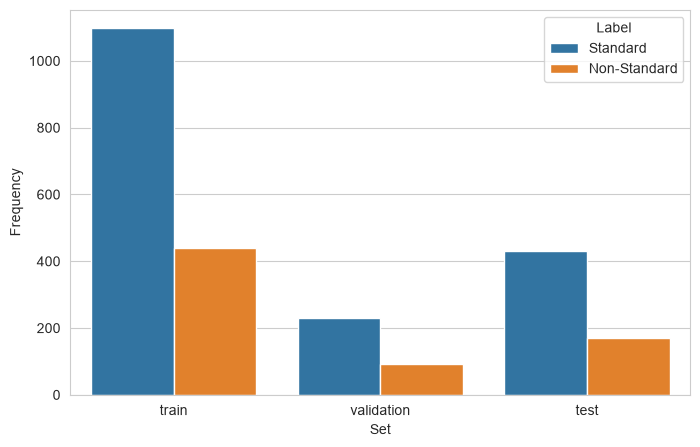

In [19]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


my_data_dir = r"C:\python_projects\ML_2\inputs\Dataset_Clean"
labels = ['Standard', 'Non-Standard']
folders = ['train', 'validation', 'test']

# Create an empty dictionary
data = {
    'Set': [],
    'Label': [],
    'Frequency': []
}

# Loop to dynamically create and append rows
for folder in folders:
    for label in labels:
        label_path = os.path.join(my_data_dir, folder, label)
        if os.path.exists(label_path):
            frequency = len(os.listdir(label_path))
            print(f"* {folder} - {label}: {frequency} images")
            row = {
                'Set': folder,
                'Label': label,
                'Frequency': frequency
            }
            for key, value in row.items():
                data[key].append(value)
        else:
            print(f" Folder not found: {label_path}")

# Convert the dictionary to a DataFrame
df_freq = pd.DataFrame(data)

print("\n")
# Plotting
sns.set_style("whitegrid")
plt.figure(figsize=(8, 5))
sns.barplot(data=df_freq, x='Set', y='Frequency', hue='Label')

plt.savefig(output_dir / 'labels_distribution.png', bbox_inches='tight', dpi=150)

plt.show()

Image data augmentation 


ImageDataGenerator 


In [20]:
import joblib

# Image dimensions
image_shape = joblib.load(output_dir / "image_shape.pkl")

# Folder for saving plots
output_dir = Path(r"C:\python_projects\ML_2\outputs\v1")

print("Image shape:", image_shape)
print("Output directory:", output_dir)

Image shape: (256, 256)
Output directory: C:\python_projects\ML_2\outputs\v1


In [21]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

Initialize ImageDataGenerator

In [22]:
augmented_image_data = ImageDataGenerator(rotation_range=20,
                                        width_shift_range=0.10,
                                        height_shift_range=0.10,
                                        shear_range=0.1,
                                        zoom_range=0.1,
                                        horizontal_flip=True,
                                        vertical_flip=True,
                                        fill_mode='nearest',
                                        rescale=1./255
                                        )

In [34]:
#image_shape='../outputs/v1/image_shape.pkl'
train_path = '../inputs/Dataset_Clean//train'
batch_size = 20  # Set batch size
train_set = augmented_image_data.flow_from_directory(train_path,
                                                    target_size=image_shape[:2],
                                                    color_mode='rgb',
                                                    batch_size=batch_size,
                                                    class_mode='binary',
                                                    shuffle=True
                                                    )

train_set.class_indices

Found 1538 images belonging to 2 classes.


{'Non-Standard': 0, 'Standard': 1}

In [35]:
validation_path = '../inputs/Dataset_Clean/validation'
test_path='../inputs/Dataset_Clean/test'

In [36]:
from pathlib import Path

# Correct training path
train_path = str(Path(r"C:\python_projects\ML_2\inputs\Dataset_Clean\train"))

# Set batch size
batch_size = 20

# Create training dataset with augmentation
train_set = augmented_image_data.flow_from_directory(
    directory=train_path,
    target_size=tuple(image_shape[:2]),
    color_mode='rgb',
    batch_size=batch_size,
    class_mode='binary',
    shuffle=True
)

# Display class labels
print(train_set.class_indices)

Found 1538 images belonging to 2 classes.
{'Non-Standard': 0, 'Standard': 1}


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

batch_size = 20

validation_set = ImageDataGenerator(
    rescale=1./255
).flow_from_directory(
    validation_path,
    target_size=image_shape[:2],
    color_mode='rgb',
    batch_size=batch_size,
    class_mode='sparse',
    shuffle=False
)

print(validation_set.class_indices)
print("Validation images:", validation_set.samples)

Found 322 images belonging to 2 classes.
{'Non-Standard': 0, 'Standard': 1}
Validation images: 322


In [ ]:
batch_size = 20
validation_set = ImageDataGenerator(rescale=1./255).flow_from_directory(validation_path,
                                                                        target_size=image_shape[:2],
                                                                        color_mode='rgb',
                                                                        batch_size=batch_size,
                                                                        class_mode='binary',
                                                                        shuffle=False
                                                                        )

validation_set.class_indices

Found 322 images belonging to 2 classes.


{'Non-Standard': 0, 'Standard': 1}

In [37]:
train_set = ImageDataGenerator(
    rescale=1./255
).flow_from_directory(
    train_path,
    target_size=image_shape[:2],
    color_mode='rgb',
    batch_size=batch_size,
    class_mode='sparse',
    shuffle=True,
    seed=42
)

Found 1538 images belonging to 2 classes.


Plot augmented training image

(20, 256, 256, 3)


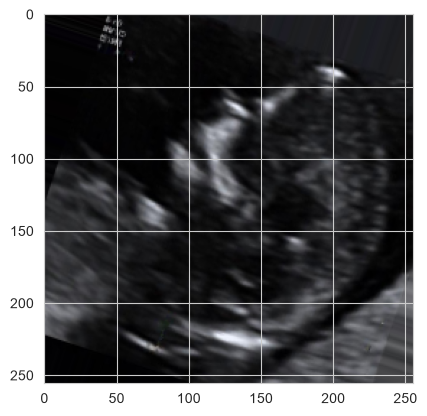

(20, 256, 256, 3)


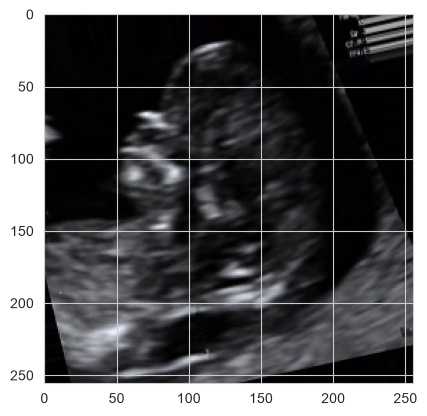

(20, 256, 256, 3)


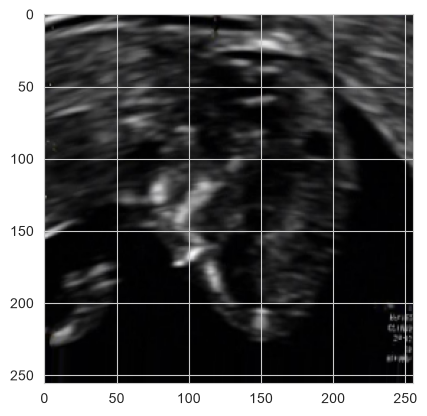

In [ ]:
import matplotlib.pyplot as plt

for _ in range(3):
    img, label = next(train_set)
    print(img.shape)  # (1,256,256,3)
    plt.imshow(img[0])
    plt.show()

Plot augmented validation image

(20, 256, 256, 3)


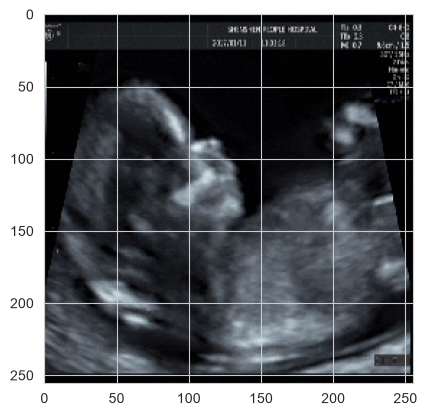

(20, 256, 256, 3)


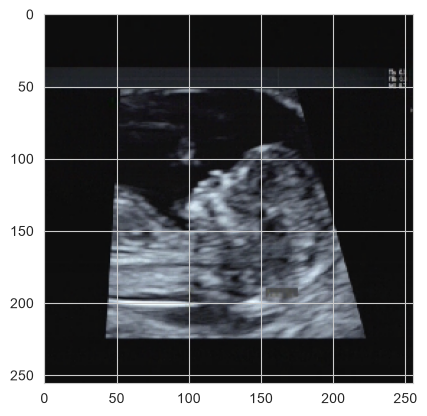

(20, 256, 256, 3)


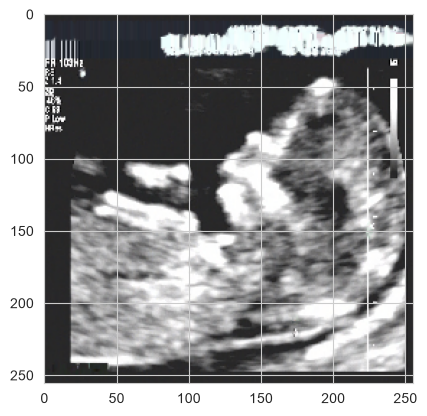

In [ ]:
for _ in range(3):
    img, label = next(validation_set)
    print(img.shape)  # (1,256,256,3)
    plt.imshow(img[0])
    plt.show()

Plot augmented test image

(20, 256, 256, 3)


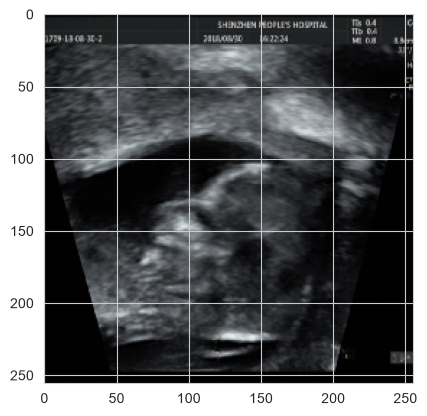

(20, 256, 256, 3)


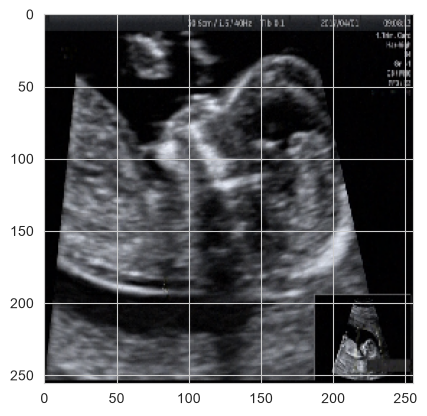

(20, 256, 256, 3)


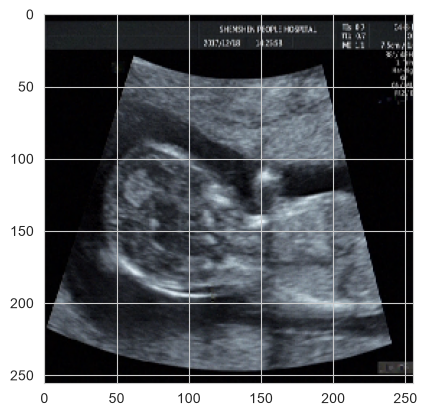

In [ ]:
for _ in range(3):
    img, label = next(test_set)
    print(img.shape)  # (1,256,256,3)
    plt.imshow(img[0])
    plt.show()

Save class_indices

In [38]:
import joblib
import os
version="v1"
file_path=f'outputs/{version}'

os.makedirs(file_path, exist_ok=True)
joblib.dump(value=train_set.class_indices,
            filename=f"{file_path}/class_indices.pkl")

['outputs/v1/class_indices.pkl']

Model Creation

ML model

Import model packages

In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense, Conv2D, MaxPooling2D

Model

In [40]:
#image_shape='C:\\python_projects\\project_5\\jupyter_notebooks\\outputs\\v1\\image_shape.pkl'
image_shape='../outputs/v1/image_shape.pkl'

The code below defines a four-block convolutional neural network (CNN) for binary classification of fetal ultrasound images into Standard and Non-standard. 

In [42]:
from tensorflow import keras
from tensorflow.keras import layers

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

inputs = keras.Input(shape=(256, 256, 1))
x = layers.Rescaling(1/255)(inputs)
x = layers.RandomRotation(0.05)(x)          # mild, ultrasound-appropriate augmentation
x = layers.RandomContrast(0.1)(x)
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(2, activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [48]:
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

def create_tf_model():
        model = Sequential()

        model.add(Input(shape=(256, 256, 3)))
        model.add(Conv2D(filters=32, kernel_size=(3, 3),
                input_shape=image_shape, activation='relu', ))
        model.add(MaxPooling2D(pool_size=(2, 2)))

        model.add(Conv2D(filters=64, kernel_size=(3, 3),
                input_shape=image_shape, activation='relu', ))
        model.add(MaxPooling2D(pool_size=(2, 2)))

        model.add(Conv2D(filters=64, kernel_size=(3, 3),
                input_shape=image_shape, activation='relu', ))
        model.add(MaxPooling2D(pool_size=(2, 2)))

        model.add(Flatten())
        model.add(Dense(128, activation='relu'))

        model.add(Dropout(0.5))
        model.add(Dense(2, activation='softmax'))

        model.compile(loss='sparse_categorical_crossentropy',
                optimizer='adam',
                metrics=['accuracy'])

        return model

In [ ]:
import os
import shutil
from pathlib import Path

# Replace with the actual folder containing dot.exe
graphviz_bin = Path(r"C:\Users\omer\windows_10_cmake_Release_Graphviz-16.1.0-win32.zip\Graphviz-16.1.0-win32\bin")

os.environ["PATH"] = str(graphviz_bin) + os.pathsep + os.environ["PATH"]

print("dot.exe exists:", (graphviz_bin / "dot.exe").exists())
print("Graphviz found:", shutil.which("dot"))

In [ ]:
C:\Users\omer\windows_10_cmake_Release_Graphviz-16.1.0-win32.zip\Graphviz-16.1.0-win32\bin

In [53]:
plot_model(
    model,
    to_file="model_plot.png",
    show_shapes=True
)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


Model Summary

In [49]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model = create_tf_model()

history = model.fit(
    train_set,
    validation_data=validation_set,
    epochs=25,
    callbacks=[early_stop],
    verbose=1
)

c:\python_projects\ML_2\venv_clean\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 51s 622ms/step - accuracy: 0.7796 - loss: 0.5446 - val_accuracy: 0.8385 - val_loss: 0.3846
Epoch 2/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 41s 536ms/step - accuracy: 0.8836 - loss: 0.2970 - val_accuracy: 0.8602 - val_loss: 0.3278
Epoch 3/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 42s 544ms/step - accuracy: 0.9103 - loss: 0.2299 - val_accuracy: 0.8975 - val_loss: 0.2185
Epoch 4/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 42s 547ms/step - accuracy: 0.9330 - loss: 0.1813 - val_accuracy: 0.9317 - val_loss: 0.1747
Epoch 5/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 45s 585ms/step - accuracy: 0.9493 - loss: 0.1364 - val_accuracy: 0.9534 - val_loss: 0.1071
Epoch 6/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 41s 535ms/step - accuracy: 0.9603 - loss: 0.0976 - val_accuracy: 0.9627 - val_loss: 0.0918
Epoch 7/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 41s 529ms/step - accuracy: 0.9701 - loss: 0.0713 - val_accuracy: 0.9689 - val_loss: 0.0891
Epoch 8/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 43s 553ms/step - accuracy: 0.9759 - loss: 0.0626 - val_accu

In [52]:
from pathlib import Path
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

# Define output directory
output_dir = Path(r"C:\python_projects\ML_2\outputs\v1")
output_dir.mkdir(parents=True, exist_ok=True)

# Define plot path
plot_path = output_dir / "model_plot.png"

# Generate CNN architecture diagram
plot_model(
    model,
    to_file=str(plot_path),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True
)

# Display the diagram
display(Image(filename=str(plot_path)))

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\python_projects\\ML_2\\outputs\\v1\\model_plot.png'

In [50]:
plot_model(
    model,
    to_file=str(plot_path),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True
)

NameError: name 'plot_path' is not defined

In [51]:
create_tf_model().summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,429,506 (28.34 MB)

 Trainable params: 7,429,506 (28.34 MB)

 Non-trainable params: 0 (0.00 B)

Early Stopping

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=3)

Fit model for model training

Save model

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [ ]:
print("image_shape:", image_shape, type(image_shape))
print("batch_size:", batch_size, type(batch_size))

print("train_set:", type(train_set))
print("validation_set:", type(validation_set))

print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

image_shape: ../outputs/v1/image_shape.pkl <class 'str'>
batch_size: 20 <class 'int'>
train_set: <class 'keras.src.legacy.preprocessing.image.DirectoryIterator'>
validation_set: <class 'keras.src.legacy.preprocessing.image.DirectoryIterator'>
Model input: (None, 256, 256, 3)
Model output: (None, 2)


In [ ]:
image_shape = (256, 256, 3)

print(image_shape)
print(type(image_shape))

(256, 256, 3)
<class 'tuple'>


In [ ]:
x_batch, y_batch = train_set[0]

print("Images:", x_batch.shape)
print("Labels:", y_batch.shape)
print("Classes:", train_set.class_indices)
print("Target size:", train_set.target_size)

TypeError: 'str' object cannot be interpreted as an integer

In [ ]:
print("Training target size:", train_set.target_size)
print("Validation target size:", validation_set.target_size)
print("Training batch size:", train_set.batch_size)
print("Validation batch size:", validation_set.batch_size)

Training target size: ('.', '.')
Validation target size: ('.', '.')
Training batch size: 20
Validation batch size: 20


In [ ]:
from pathlib import Path
from tensorflow.keras.preprocessing.image import ImageDataGenerator

image_shape = (256, 256, 3)
batch_size = 20

dataset_path = Path(r"C:\python_projects\ML_2\inputs\Dataset_Clean")

train_path = str(dataset_path / "train")
validation_path = str(dataset_path / "validation")

train_set = ImageDataGenerator(
    rescale=1./255
).flow_from_directory(
    directory=train_path,
    target_size=(256, 256),
    color_mode="rgb",
    batch_size=20,
    class_mode="sparse",
    shuffle=True,
    seed=42
)

validation_set = ImageDataGenerator(
    rescale=1./255
).flow_from_directory(
    directory=validation_path,
    target_size=(256, 256),
    color_mode="rgb",
    batch_size=20,
    class_mode="sparse",
    shuffle=False
)

Found 1538 images belonging to 2 classes.
Found 322 images belonging to 2 classes.


In [ ]:
# Create CNN model
model = create_tf_model()

# Train model
history = model.fit(
    train_set,
    epochs=25,
    validation_data=validation_set,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 45s 556ms/step - accuracy: 0.8114 - loss: 0.4476 - val_accuracy: 0.8540 - val_loss: 0.3076
Epoch 2/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 40s 520ms/step - accuracy: 0.8804 - loss: 0.2878 - val_accuracy: 0.9193 - val_loss: 0.2244
Epoch 3/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 39s 499ms/step - accuracy: 0.9129 - loss: 0.2111 - val_accuracy: 0.9224 - val_loss: 0.1907
Epoch 4/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 38s 495ms/step - accuracy: 0.9493 - loss: 0.1310 - val_accuracy: 0.9596 - val_loss: 0.1005
Epoch 5/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 38s 497ms/step - accuracy: 0.9701 - loss: 0.0793 - val_accuracy: 0.9596 - val_loss: 0.1317
Epoch 6/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 41s 524ms/step - accuracy: 0.9824 - loss: 0.0447 - val_accuracy: 0.9752 - val_loss: 0.1006
Epoch 7/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 40s 519ms/step - accuracy: 0.9785 - loss: 0.0583 - val_accuracy: 0.9752 - val_loss: 0.0752
Epoch 8/25
77/77 ━━━━━━━━━━━━━━━━━━━━ 39s 501ms/step - accuracy: 0.9928 - loss: 0.0219 - val_accu

Below is the model with epochs instead of att Tensorflow will determine as in above 

In [24]:
model = create_tf_model()

model.summary()

print("Training images:", train_set.samples)
print("Validation images:", validation_set.samples)
print("Classes:", train_set.class_indices)

NameError: name 'create_tf_model' is not defined

In [ ]:
model.save('outputs/v1/my_model.keras')

Model Performance

Model learning curve

    accuracy      loss  val_accuracy  val_loss
12  0.992848  0.016649      0.981366  0.096895
13  0.996749  0.010911      0.984472  0.092340
14  0.999350  0.004115      0.975155  0.138655
15  0.996099  0.010478      0.975155  0.200522
16  0.992198  0.027975      0.978261  0.099053


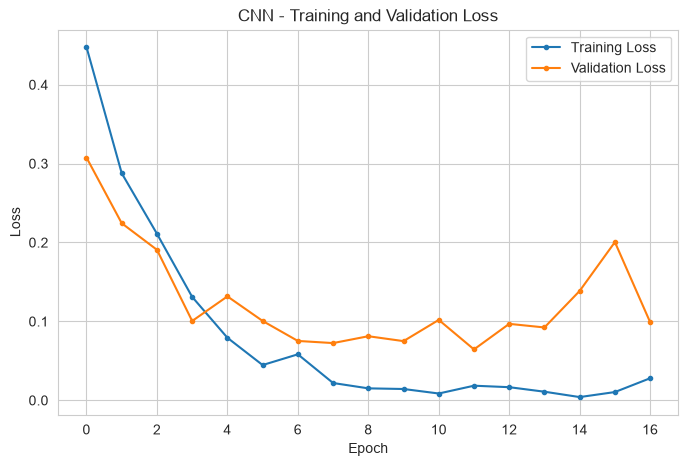

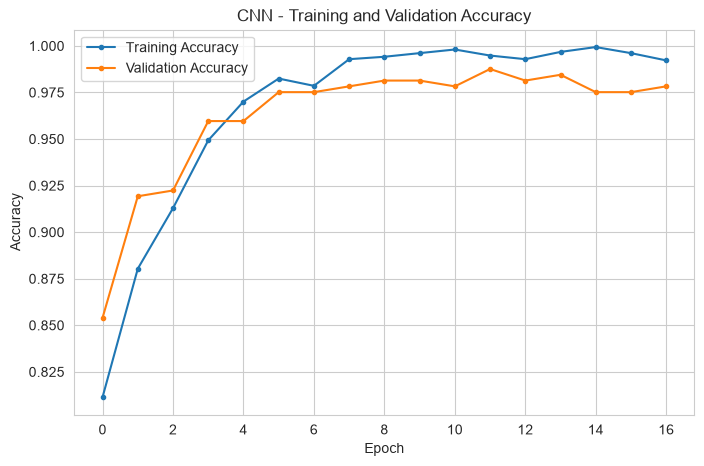

Plots saved to: C:\python_projects\ML_2\outputs\v1


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Directory for saving training plots
file_path = Path(r"C:\python_projects\ML_2\outputs\v1")
file_path.mkdir(parents=True, exist_ok=True)

# Convert training history to DataFrame
losses = pd.DataFrame(history.history)

print(losses.tail())

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(losses["loss"], ".-", label="Training Loss")
plt.plot(losses["val_loss"], ".-", label="Validation Loss")

plt.title("CNN - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    file_path / "model_training_losses.png",
    bbox_inches="tight",
    dpi=150
)
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(losses["accuracy"], ".-", label="Training Accuracy")
plt.plot(losses["val_accuracy"], ".-", label="Validation Accuracy")

plt.title("CNN - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    file_path / "model_training_acc.png",
    bbox_inches="tight",
    dpi=150
)
plt.show()

print("Plots saved to:", file_path)


Model Evaluation

Load saved model

In [ ]:
from keras.models import load_model
model = load_model('outputs/v1/my_model.keras')

c:\python_projects\ML_2\venv_clean\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_10', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Evaluate model on test set

In [ ]:
import os
test_path = os.path.abspath("../inputs/Dataset/test")
print(test_path)

c:\python_projects\ML_2\inputs\Dataset\test


In [ ]:
from keras.models import load_model
model = load_model('outputs/v1/my_model.keras')

In [ ]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.19.0
Keras: 3.15.1


In [ ]:
evaluation = model.evaluate(test_set)

31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 502ms/step - accuracy: 0.3671 - loss: 0.6996


In [ ]:
print(model.input_shape)

(None, 256, 256, 3)


Save evaluation pickle

In [ ]:
joblib.dump(value=evaluation,
            filename=f"outputs/v1/evaluation.pkl")

['outputs/v1/evaluation.pkl']

Predict on new data

Load a random image as PIL

Image shape: (256, 256), Image mode: RGB


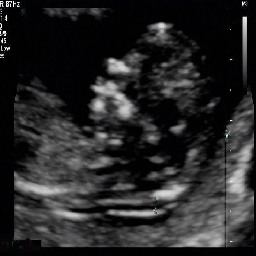

In [ ]:

from tensorflow.keras.preprocessing import image
import os

test_path = '../inputs/Dataset_Clean/test'
image_shape = (256, 256)

pointer = 66
label = labels[0]  # select Healthy or powdery_mildew

pil_image = image.load_img(test_path + '/' + label + '/' + os.listdir(test_path+'/' + label)[pointer],
                        target_size=image_shape, color_mode='rgb')
print(f'Image shape: {pil_image.size}, Image mode: {pil_image.mode}')
pil_image

Convert image to array and prepare for prediction

In [ ]:
my_image = image.img_to_array(pil_image)
my_image = np.expand_dims(my_image, axis=0)/255
print(my_image.shape)

(1, 256, 256, 3)


Predict class probabilities

In [32]:
pred_proba = model.predict(my_image)[0, 0]

target_map = {v: k for k, v in train_set.class_indices.items()}
pred_class = target_map[pred_proba > 0.5]

if pred_class == target_map[0]:
    pred_proba = 1 - pred_proba

print(pred_proba)
print(pred_class)

NameError: name 'model' is not defined

In [33]:
import numpy as np

test_set.reset()

predictions = model.predict(test_set, verbose=1)

print("First 10 predictions:")
print(np.round(predictions[:10], 4))

print("\nAverage probabilities:")
print(np.mean(predictions, axis=0))

print("\nMinimum probabilities:")
print(np.min(predictions, axis=0))

print("\nMaximum probabilities:")
print(np.max(predictions, axis=0))

print("\nPredicted class distribution:")
print(np.bincount(np.argmax(predictions, axis=1), minlength=2))

NameError: name 'model' is not defined

In [25]:
print("Training:", train_set.class_indices)
print("Validation:", validation_set.class_indices)
print("Test:", test_set.class_indices)

NameError: name 'train_set' is not defined

In [ ]:
!cat .gitignore

'cat' is not recognized as an internal or external command,
operable program or batch file.


Create a test generator from the test folder within the Dataset_Clean 

In [ ]:
from pathlib import Path
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = Path(r"C:\python_projects\ML_2\inputs\Dataset_Clean")
test_path = dataset_path / "test"

if not test_path.is_dir():
    raise FileNotFoundError(f"Test folder not found: {test_path}")

test_set = ImageDataGenerator(
    rescale=1./255
).flow_from_directory(
    directory=str(test_path),
    target_size=(256, 256),
    color_mode="rgb",
    batch_size=20,
    class_mode="sparse",
    shuffle=False
)

print("Test images:", test_set.samples)
print("Test classes:", test_set.class_indices)

Found 602 images belonging to 2 classes.
Test images: 602
Test classes: {'Non-Standard': 0, 'Standard': 1}


Evaluate the trained CNN 

In [ ]:
# Check that class mappings match
assert train_set.class_indices == test_set.class_indices

# Evaluate trained model
test_loss, test_accuracy = model.evaluate(
    test_set,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 235ms/step - accuracy: 0.3671 - loss: 0.6996
Test Loss: 0.6996
Test Accuracy: 0.3671


In [ ]:
import pickle
from pathlib import Path

output_dir = Path(r"C:\python_projects\ML_2\outputs\v1")
output_dir.mkdir(parents=True, exist_ok=True)

evaluation = {
    "Loss": float(test_loss),
    "Accuracy": float(test_accuracy)
}

evaluation_path = output_dir / "evaluation.pkl"

with open(evaluation_path, "wb") as file:
    pickle.dump(evaluation, file)

print("Evaluation saved to:", evaluation_path)

Evaluation saved to: C:\python_projects\ML_2\outputs\v1\evaluation.pkl


In [ ]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

model_path = (
    r"C:\python_projects\ML_2"
    r"\jupyter_notebooks\outputs\v1\my_model.keras"
)

model = tf.keras.models.load_model(
    model_path,
    compile=False
)

model.summary()

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

TensorFlow: 2.19.0
Keras: 3.15.1


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_35 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,429,506 (28.34 MB)

 Trainable params: 7,429,506 (28.34 MB)

 Non-trainable params: 0 (0.00 B)

Input shape: (None, 256, 256, 3)
Output shape: (None, 2)


In [ ]:
!git status

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   ../app_pages/page_live_predictions.py
	modified:   ../app_pages/page_summary.py
	modified:   Modelling and Evaluating.ipynb
	modified:   outputs/v1/evaluation.pkl
	modified:   outputs/v1/model_training_acc.png
	modified:   outputs/v1/model_training_losses.png
	modified:   outputs/v1/my_model.keras

no changes added to commit (use "git add" and/or "git commit -a")


In [26]:

from pathlib import Path
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = Path(r"C:\python_projects\ML_2\inputs\Dataset_Clean")

data_generator = ImageDataGenerator(rescale=1./255)

train_set = data_generator.flow_from_directory(
    directory=str(dataset_path / "train"),
    target_size=(256, 256),
    color_mode="rgb",
    batch_size=20,
    class_mode="sparse",
    shuffle=False
)

validation_set = data_generator.flow_from_directory(
    directory=str(dataset_path / "validation"),
    target_size=(256, 256),
    color_mode="rgb",
    batch_size=20,
    class_mode="sparse",
    shuffle=False
)

test_set = data_generator.flow_from_directory(
    directory=str(dataset_path / "test"),
    target_size=(256, 256),
    color_mode="rgb",
    batch_size=20,
    class_mode="sparse",
    shuffle=False
)


Found 1538 images belonging to 2 classes.
Found 322 images belonging to 2 classes.
Found 602 images belonging to 2 classes.


In [27]:
print("Training:", train_set.class_indices)
print("Validation:", validation_set.class_indices)
print("Test:", test_set.class_indices)


Training: {'Non-Standard': 0, 'Standard': 1}
Validation: {'Non-Standard': 0, 'Standard': 1}
Test: {'Non-Standard': 0, 'Standard': 1}


In [28]:
import numpy as np

for name, dataset in [
    ("Training", train_set),
    ("Validation", validation_set),
    ("Test", test_set)
]:
    counts = np.bincount(dataset.classes, minlength=2)

    print(f"\n{name}:")
    print("Non-Standard:", counts[0])
    print("Standard:", counts[1])
    print("Total:", dataset.samples)


Training:
Non-Standard: 440
Standard: 1098
Total: 1538

Validation:
Non-Standard: 93
Standard: 229
Total: 322

Test:
Non-Standard: 171
Standard: 431
Total: 602


In [29]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

test_set.reset()

predictions = model.predict(test_set, verbose=1)

y_pred = np.argmax(predictions, axis=1)
y_true = test_set.classes

print("Predicted Non-Standard:", np.sum(y_pred == 0))
print("Predicted Standard:", np.sum(y_pred == 1))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Non-Standard", "Standard"],
        zero_division=0
    )
)

NameError: name 'model' is not defined

In [30]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

test_set.reset()

predictions = model.predict(test_set, verbose=1)

y_pred = np.argmax(predictions, axis=1)
y_true = test_set.classes

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Non-Standard", "Standard"],
        zero_division=0
    )
)

NameError: name 'model' is not defined

In [ ]:
!git add .

In [ ]:
!git commit -am " Added model and  new plots "

[main 1dbb22b1]  Added model and  new plots
 7 files changed, 134 insertions(+), 148 deletions(-)


In [ ]:
!git push

bash: line 1: /dev/tty: No such device or address
error: failed to execute prompt script (exit code 1)
fatal: could not read Username for 'https://github.com': No such file or directory
